In [1]:
import os
import re  
import math
import pickle
import zipfile
from collections import defaultdict

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.colors import Normalize
from mpl_toolkits.mplot3d import Axes3D  

import h5py
from scipy import signal
from scipy.stats import (zscore, ks_2samp, linregress, pearsonr)
from scipy.signal import (convolve, windows, resample)
from scipy.ndimage import gaussian_filter1d

from sklearn.preprocessing import (PolynomialFeatures, StandardScaler)
from sklearn.model_selection import (train_test_split, cross_val_score, KFold,GridSearchCV)


from scipy.signal import convolve, windows
from scipy.sparse import csr_matrix
from sklearn.model_selection import train_test_split
from pyglmnet import GLM


from sklearn.linear_model import PoissonRegressor
from sklearn.pipeline import make_pipeline
from scipy.interpolate import interp1d


In [2]:
session_files1 = {
    "Day01": [
        'E3_MB01_Day01High_1.pkl', 'E3_MB01_Day01High_11.pkl', 'E3_MB01_Day01High_14.pkl',
        'E3_MB01_Day01High_17.pkl', 'E3_MB01_Day01High_21.pkl', 'E3_MB01_Day01High_24.pkl',
        'E3_MB01_Day01High_27.pkl', 'E3_MB01_Day01High_30.pkl', 'E3_MB01_Day01High_6.pkl',
        'E3_MB01_Day01High_9.pkl'
    ],
    "Day03": [
        'E3_MB01_Day03High_11.pkl', 'E3_MB01_Day03High_14.pkl', 'E3_MB01_Day03High_18.pkl',
        'E3_MB01_Day03High_21.pkl', 'E3_MB01_Day03High_23.pkl', 'E3_MB01_Day03High_26.pkl',
        'E3_MB01_Day03High_29.pkl', 'E3_MB01_Day03High_3.pkl', 'E3_MB01_Day03High_4.pkl',
        'E3_MB01_Day03High_9.pkl'
    ],
    "Day04": [
        'E3_MB01_Day04High_1.pkl', 'E3_MB01_Day04High_10.pkl', 'E3_MB01_Day04High_13.pkl',
        'E3_MB01_Day04High_17.pkl', 'E3_MB01_Day04High_20.pkl', 'E3_MB01_Day04High_23.pkl',
        'E3_MB01_Day04High_25.pkl', 'E3_MB01_Day04High_29.pkl', 'E3_MB01_Day04High_30.pkl',
        'E3_MB01_Day04High_6.pkl', 'E3_MB01_Day04High_9.pkl'
    ],
    "Day05": [
        'E3_MB01_Day05High_1.pkl', 'E3_MB01_Day05High_10.pkl', 'E3_MB01_Day05High_13.pkl',
        'E3_MB01_Day05High_18.pkl', 'E3_MB01_Day05High_21.pkl', 'E3_MB01_Day05High_23.pkl',
        'E3_MB01_Day05High_26.pkl', 'E3_MB01_Day05High_28.pkl', 'E3_MB01_Day05High_5.pkl',
        'E3_MB01_Day05High_9.pkl'
    ],
    "Day06": [
        'E3_MB01_Day06High_10.pkl', 'E3_MB01_Day06High_14.pkl', 'E3_MB01_Day06High_18.pkl',
        'E3_MB01_Day06High_21.pkl', 'E3_MB01_Day06High_22.pkl', 'E3_MB01_Day06High_26.pkl',
        'E3_MB01_Day06High_3.pkl', 'E3_MB01_Day06High_30.pkl', 'E3_MB01_Day06High_5.pkl',
        'E3_MB01_Day06High_9.pkl'
    ],
    "Day07": [
        'E3_MB01_Day07High_1.pkl', 'E3_MB01_Day07High_10.pkl', 'E3_MB01_Day07High_14.pkl',
        'E3_MB01_Day07High_18.pkl', 'E3_MB01_Day07High_19.pkl', 'E3_MB01_Day07High_23.pkl',
        'E3_MB01_Day07High_26.pkl', 'E3_MB01_Day07High_28.pkl', 'E3_MB01_Day07High_5.pkl',
        'E3_MB01_Day07High_9.pkl'
        
    ],
    
    "Day08": ['E3_MB01_Day08High_12.pkl', 'E3_MB01_Day08High_13.pkl', 'E3_MB01_Day08High_17.pkl',
              'E3_MB01_Day08High_21.pkl', 'E3_MB01_Day08High_23.pkl', 'E3_MB01_Day08High_25.pkl',
              'E3_MB01_Day08High_3.pkl', 'E3_MB01_Day08High_30.pkl', 'E3_MB01_Day08High_7.pkl'],
    "Day09": ['E3_MB01_Day09High_1.pkl', 'E3_MB01_Day09High_13.pkl', 'E3_MB01_Day09High_15.pkl',
              'E3_MB01_Day09High_18.pkl', 'E3_MB01_Day09High_23.pkl', 'E3_MB01_Day09High_26.pkl',
              'E3_MB01_Day09High_27.pkl', 'E3_MB01_Day09High_4.pkl', 'E3_MB01_Day09High_8.pkl',
              'E3_MB01_Day09High_9.pkl'],
    "Day10": ['E3_MB01_Day10High_1.pkl', 'E3_MB01_Day10High_10.pkl', 'E3_MB01_Day10High_15.pkl',
              'E3_MB01_Day10High_18.pkl', 'E3_MB01_Day10High_19.pkl', 'E3_MB01_Day10High_22.pkl',
              'E3_MB01_Day10High_25.pkl', 'E3_MB01_Day10High_30.pkl', 'E3_MB01_Day10High_5.pkl',
              'E3_MB01_Day10High_7.pkl'],
    "Day11": ['E3_MB01_Day11High_12.pkl', 'E3_MB01_Day11High_15.pkl', 'E3_MB01_Day11High_18.pkl',
              'E3_MB01_Day11High_20.pkl', 'E3_MB01_Day11High_24.pkl', 'E3_MB01_Day11High_25.pkl',
              'E3_MB01_Day11High_28.pkl', 'E3_MB01_Day11High_3.pkl', 'E3_MB01_Day11High_4.pkl',
              'E3_MB01_Day11High_8.pkl'],
    "Day12": ['E3_MB01_Day12High_12.pkl', 'E3_MB01_Day12High_15.pkl', 'E3_MB01_Day12High_17.pkl',
              'E3_MB01_Day12High_2.pkl', 'E3_MB01_Day12High_20.pkl', 'E3_MB01_Day12High_24.pkl',
              'E3_MB01_Day12High_25.pkl', 'E3_MB01_Day12High_28.pkl', 'E3_MB01_Day12High_4.pkl',
              'E3_MB01_Day12High_7.pkl'],
    "Day13": ['E3_MB01_Day13High_1.pkl', 'E3_MB01_Day13High_12.pkl', 'E3_MB01_Day13High_14.pkl',
              'E3_MB01_Day13High_16.pkl', 'E3_MB01_Day13High_19.pkl', 'E3_MB01_Day13High_23.pkl',
              'E3_MB01_Day13High_25.pkl', 'E3_MB01_Day13High_30.pkl', 'E3_MB01_Day13High_5.pkl',
              'E3_MB01_Day13High_9.pkl'],
    "Day14": ['E3_MB01_Day14High_12.pkl', 'E3_MB01_Day14High_15.pkl', 'E3_MB01_Day14High_18.pkl',
              'E3_MB01_Day14High_19.pkl', 'E3_MB01_Day14High_22.pkl', 'E3_MB01_Day14High_26.pkl',
              'E3_MB01_Day14High_28.pkl', 'E3_MB01_Day14High_3.pkl', 'E3_MB01_Day14High_5.pkl',
              'E3_MB01_Day14High_8.pkl']

}



#######################





session_files3 = {
    "Day01": ['E3_MB03_Day01High_12.pkl', 'E3_MB03_Day01High_14.pkl', 'E3_MB03_Day01High_16.pkl',
              'E3_MB03_Day01High_19.pkl', 'E3_MB03_Day01High_23.pkl', 'E3_MB03_Day01High_27.pkl',
              'E3_MB03_Day01High_29.pkl', 'E3_MB03_Day01High_3.pkl', 'E3_MB03_Day01High_4.pkl',
              'E3_MB03_Day01High_8.pkl'],
    "Day02": ['E3_MB03_Day02High_12.pkl', 'E3_MB03_Day02High_15.pkl', 'E3_MB03_Day02High_17.pkl',
              'E3_MB03_Day02High_19.pkl', 'E3_MB03_Day02High_2.pkl', 'E3_MB03_Day02High_24.pkl',
              'E3_MB03_Day02High_26.pkl', 'E3_MB03_Day02High_29.pkl', 'E3_MB03_Day02High_6.pkl',
              'E3_MB03_Day02High_8.pkl'],
    "Day03": ['E3_MB03_Day03High_10.pkl', 'E3_MB03_Day03High_15.pkl', 'E3_MB03_Day03High_17.pkl',
              'E3_MB03_Day03High_2.pkl', 'E3_MB03_Day03High_21.pkl', 'E3_MB03_Day03High_23.pkl',
              'E3_MB03_Day03High_26.pkl', 'E3_MB03_Day03High_29.pkl', 'E3_MB03_Day03High_5.pkl',
              'E3_MB03_Day03High_9.pkl'],
    "Day04": ['E3_MB03_Day04High_1.pkl', 'E3_MB03_Day04High_11.pkl', 'E3_MB03_Day04High_15.pkl',
              'E3_MB03_Day04High_16.pkl', 'E3_MB03_Day04High_20.pkl', 'E3_MB03_Day04High_23.pkl',
              'E3_MB03_Day04High_26.pkl', 'E3_MB03_Day04High_28.pkl', 'E3_MB03_Day04High_4.pkl',
              'E3_MB03_Day04High_9.pkl'],
    "Day05": ['E3_MB03_Day05High_12.pkl', 'E3_MB03_Day05High_15.pkl', 'E3_MB03_Day05High_17.pkl',
              'E3_MB03_Day05High_20.pkl', 'E3_MB03_Day05High_22.pkl', 'E3_MB03_Day05High_26.pkl',
              'E3_MB03_Day05High_29.pkl', 'E3_MB03_Day05High_3.pkl', 'E3_MB03_Day05High_4.pkl',
              'E3_MB03_Day05High_7.pkl'],
    "Day07": ['E3_MB03_Day07High_11.pkl', 'E3_MB03_Day07High_13.pkl', 'E3_MB03_Day07High_18.pkl',
              'E3_MB03_Day07High_19.pkl', 'E3_MB03_Day07High_22.pkl', 'E3_MB03_Day07High_27.pkl',
              'E3_MB03_Day07High_29.pkl', 'E3_MB03_Day07High_3.pkl', 'E3_MB03_Day07High_7.pkl'],
    "Day10": ['E3_MB03_Day10High_12.pkl', 'E3_MB03_Day10High_13.pkl', 'E3_MB03_Day10High_17.pkl',
              'E3_MB03_Day10High_21.pkl', 'E3_MB03_Day10High_22.pkl', 'E3_MB03_Day10High_25.pkl',
              'E3_MB03_Day10High_3.pkl', 'E3_MB03_Day10High_30.pkl', 'E3_MB03_Day10High_5.pkl',
              'E3_MB03_Day10High_8.pkl'],
    "Day11": ['E3_MB03_Day11High_10.pkl', 'E3_MB03_Day11High_14.pkl', 'E3_MB03_Day11High_18.pkl',
              'E3_MB03_Day11High_20.pkl', 'E3_MB03_Day11High_23.pkl', 'E3_MB03_Day11High_26.pkl',
              'E3_MB03_Day11High_3.pkl', 'E3_MB03_Day11High_30.pkl', 'E3_MB03_Day11High_6.pkl',
              'E3_MB03_Day11High_9.pkl'],
    "Day12": ['E3_MB03_Day12High_12.pkl', 'E3_MB03_Day12High_13.pkl', 'E3_MB03_Day12High_17.pkl',
              'E3_MB03_Day12High_21.pkl', 'E3_MB03_Day12High_22.pkl', 'E3_MB03_Day12High_25.pkl',
              'E3_MB03_Day12High_29.pkl', 'E3_MB03_Day12High_3.pkl', 'E3_MB03_Day12High_5.pkl',
              'E3_MB03_Day12High_8.pkl'],
    "Day13": ['E3_MB03_Day13High_12.pkl', 'E3_MB03_Day13High_13.pkl', 'E3_MB03_Day13High_18.pkl',
              'E3_MB03_Day13High_19.pkl', 'E3_MB03_Day13High_2.pkl', 'E3_MB03_Day13High_24.pkl',
              'E3_MB03_Day13High_27.pkl', 'E3_MB03_Day13High_29.pkl', 'E3_MB03_Day13High_5.pkl',
              'E3_MB03_Day13High_7.pkl'],
    "Day14": ['E3_MB03_Day14High_12.pkl', 'E3_MB03_Day14High_13.pkl', 'E3_MB03_Day14High_16.pkl',
              'E3_MB03_Day14High_21.pkl', 'E3_MB03_Day14High_24.pkl', 'E3_MB03_Day14High_26.pkl',
              'E3_MB03_Day14High_29.pkl', 'E3_MB03_Day14High_3.pkl', 'E3_MB03_Day14High_4.pkl',
              'E3_MB03_Day14High_8.pkl']
}


#######################



session_files2 = {
    "Day02": [
        'E3_MB02_Day02High_10.pkl', 'E3_MB02_Day02High_14.pkl', 'E3_MB02_Day02High_18.pkl',
        'E3_MB02_Day02High_2.pkl', 'E3_MB02_Day02High_20.pkl', 'E3_MB02_Day02High_24.pkl',
        'E3_MB02_Day02High_27.pkl', 'E3_MB02_Day02High_29.pkl', 'E3_MB02_Day02High_6.pkl',
        'E3_MB02_Day02High_9.pkl'
    ],
    "Day03": [
        'E3_MB02_Day03High_11.pkl', 'E3_MB02_Day03High_13.pkl', 'E3_MB02_Day03High_18.pkl',
        'E3_MB02_Day03High_21.pkl', 'E3_MB02_Day03High_24.pkl', 'E3_MB02_Day03High_26.pkl',
        'E3_MB02_Day03High_29.pkl', 'E3_MB02_Day03High_3.pkl', 'E3_MB02_Day03High_5.pkl',
        'E3_MB02_Day03High_7.pkl'
    ],
    "Day04": [
        'E3_MB02_Day04High_11.pkl', 'E3_MB02_Day04High_14.pkl', 'E3_MB02_Day04High_16.pkl',
        'E3_MB02_Day04High_2.pkl', 'E3_MB02_Day04High_21.pkl', 'E3_MB02_Day04High_22.pkl',
        'E3_MB02_Day04High_27.pkl', 'E3_MB02_Day04High_30.pkl', 'E3_MB02_Day04High_5.pkl',
        'E3_MB02_Day04High_7.pkl'
    ],
    "Day07": [
        'E3_MB02_Day07High_1.pkl', 'E3_MB02_Day07High_12.pkl', 'E3_MB02_Day07High_13.pkl',
        'E3_MB02_Day07High_16.pkl', 'E3_MB02_Day07High_19.pkl', 'E3_MB02_Day07High_24.pkl',
        'E3_MB02_Day07High_27.pkl', 'E3_MB02_Day07High_30.pkl', 'E3_MB02_Day07High_4.pkl',
        'E3_MB02_Day07High_9.pkl'
    ],
    "Day13": [
        'E3_MB02_Day13High_1.pkl', 'E3_MB02_Day13High_11.pkl', 'E3_MB02_Day13High_13.pkl',
        'E3_MB02_Day13High_18.pkl', 'E3_MB02_Day13High_20.pkl', 'E3_MB02_Day13High_23.pkl',
        'E3_MB02_Day13High_26.pkl', 'E3_MB02_Day13High_28.pkl', 'E3_MB02_Day13High_4.pkl',
        'E3_MB02_Day13High_8.pkl'
    ]
}



#######################




session_files4 = {
    "Day01": ['E3_MB04_Day01High_16.pkl', 'E3_MB04_Day01High_19.pkl', 'E3_MB04_Day01High_2.pkl',
              'E3_MB04_Day01High_24.pkl', 'E3_MB04_Day01High_26.pkl', 'E3_MB04_Day01High_30.pkl',
              'E3_MB04_Day01High_6.pkl', 'E3_MB04_Day01High_8.pkl'],
    "Day03": ['E3_MB04_Day03High_10.pkl', 'E3_MB04_Day03High_14.pkl', 'E3_MB04_Day03High_17.pkl',
              'E3_MB04_Day03High_19.pkl', 'E3_MB04_Day03High_22.pkl', 'E3_MB04_Day03High_27.pkl',
              'E3_MB04_Day03High_28.pkl', 'E3_MB04_Day03High_3.pkl', 'E3_MB04_Day03High_5.pkl',
              'E3_MB04_Day03High_8.pkl'],
    "Day07": ['E3_MB04_Day07High_15.pkl', 'E3_MB04_Day07High_29.pkl', 'E3_MB04_Day07High_6.pkl',
              'E3_MB04_Day07High_8.pkl'],
    "Day08": ['E3_MB04_Day08High_11.pkl', 'E3_MB04_Day08High_13.pkl', 'E3_MB04_Day08High_18.pkl',
              'E3_MB04_Day08High_19.pkl', 'E3_MB04_Day08High_2.pkl', 'E3_MB04_Day08High_22.pkl',
              'E3_MB04_Day08High_27.pkl', 'E3_MB04_Day08High_28.pkl', 'E3_MB04_Day08High_6.pkl',
              'E3_MB04_Day08High_9.pkl'],
    "Day09": ['E3_MB04_Day09High_1.pkl', 'E3_MB04_Day09High_19.pkl', 'E3_MB04_Day09High_24.pkl',
              'E3_MB04_Day09High_27.pkl', 'E3_MB04_Day09High_30.pkl', 'E3_MB04_Day09High_6.pkl'],
    "Day10": ['E3_MB04_Day10High_11.pkl', 'E3_MB04_Day10High_15.pkl', 'E3_MB04_Day10High_17.pkl',
              'E3_MB04_Day10High_2.pkl', 'E3_MB04_Day10High_21.pkl', 'E3_MB04_Day10High_22.pkl',
              'E3_MB04_Day10High_26.pkl', 'E3_MB04_Day10High_28.pkl', 'E3_MB04_Day10High_4.pkl',
              'E3_MB04_Day10High_9.pkl'],
    "Day11": ['E3_MB04_Day11High_10.pkl', 'E3_MB04_Day11High_14.pkl', 'E3_MB04_Day11High_16.pkl',
              'E3_MB04_Day11High_2.pkl', 'E3_MB04_Day11High_21.pkl', 'E3_MB04_Day11High_23.pkl',
              'E3_MB04_Day11High_27.pkl', 'E3_MB04_Day11High_28.pkl', 'E3_MB04_Day11High_4.pkl',
              'E3_MB04_Day11High_9.pkl'],
    
    "Day12": ['E3_MB04_Day12High_2.pkl', 'E3_MB04_Day12High_5.pkl', 'E3_MB04_Day12High_9.pkl',
              'E3_MB04_Day12High_12.pkl', 'E3_MB04_Day12High_14.pkl', 'E3_MB04_Day12High_18.pkl',
              'E3_MB04_Day12High_19.pkl', 'E3_MB04_Day12High_23.pkl', 'E3_MB04_Day12High_26.pkl',
              'E3_MB04_Day12High_29.pkl'],
        
    "Day13": ['E3_MB04_Day13High_3.pkl', 'E3_MB04_Day13High_4.pkl', 'E3_MB04_Day13High_8.pkl',
              'E3_MB04_Day13High_12.pkl', 'E3_MB04_Day13High_14.pkl', 'E3_MB04_Day13High_18.pkl',
              'E3_MB04_Day13High_19.pkl', 'E3_MB04_Day13High_24.pkl', 'E3_MB04_Day13High_27.pkl',
              'E3_MB04_Day13High_30.pkl'],
            
    "Day14": ['E3_MB04_Day14High_3.pkl', 'E3_MB04_Day14High_4.pkl', 'E3_MB04_Day14High_8.pkl',
              'E3_MB04_Day14High_11.pkl', 'E3_MB04_Day14High_13.pkl', 'E3_MB04_Day14High_18.pkl',
              'E3_MB04_Day14High_21.pkl', 'E3_MB04_Day14High_25.pkl', 'E3_MB04_Day14High_28.pkl']
}



#######################



session_files7 = {
    "Day01": [
        'E3_MB07_Day01High_10.pkl', 'E3_MB07_Day01High_13.pkl', 'E3_MB07_Day01High_17.pkl',
        'E3_MB07_Day01High_2.pkl', 'E3_MB07_Day01High_21.pkl', 'E3_MB07_Day01High_24.pkl',
        'E3_MB07_Day01High_26.pkl', 'E3_MB07_Day01High_28.pkl', 'E3_MB07_Day01High_5.pkl',
        'E3_MB07_Day01High_9.pkl'
    ],
    "Day02": [
        'E3_MB07_Day02High_10.pkl', 'E3_MB07_Day02High_15.pkl', 'E3_MB07_Day02High_17.pkl',
        'E3_MB07_Day02High_19.pkl', 'E3_MB07_Day02High_23.pkl', 'E3_MB07_Day02High_27.pkl',
        'E3_MB07_Day02High_3.pkl', 'E3_MB07_Day02High_30.pkl', 'E3_MB07_Day02High_5.pkl',
        'E3_MB07_Day02High_9.pkl'
    ],
    "Day03": [
        'E3_MB07_Day03High_1.pkl', 'E3_MB07_Day03High_10.pkl', 'E3_MB07_Day03High_15.pkl',
        'E3_MB07_Day03High_18.pkl', 'E3_MB07_Day03High_19.pkl', 'E3_MB07_Day03High_22.pkl',
        'E3_MB07_Day03High_25.pkl', 'E3_MB07_Day03High_30.pkl', 'E3_MB07_Day03High_5.pkl',
        'E3_MB07_Day03High_7.pkl'
    ],
    "Day04": [
        'E3_MB07_Day04High_11.pkl', 'E3_MB07_Day04High_15.pkl', 'E3_MB07_Day04High_18.pkl',
        'E3_MB07_Day04High_21.pkl', 'E3_MB07_Day04High_23.pkl', 'E3_MB07_Day04High_27.pkl',
        'E3_MB07_Day04High_28.pkl', 'E3_MB07_Day04High_3.pkl', 'E3_MB07_Day04High_6.pkl',
        'E3_MB07_Day04High_7.pkl'
    ],
    "Day05": [
        'E3_MB07_Day05High_12.pkl', 'E3_MB07_Day05High_15.pkl', 'E3_MB07_Day05High_16.pkl',
        'E3_MB07_Day05High_19.pkl', 'E3_MB07_Day05High_24.pkl', 'E3_MB07_Day05High_26.pkl',
        'E3_MB07_Day05High_3.pkl', 'E3_MB07_Day05High_30.pkl', 'E3_MB07_Day05High_5.pkl',
        'E3_MB07_Day05High_7.pkl'
    ],
    "Day06": [
        'E3_MB07_Day06High_10.pkl', 'E3_MB07_Day06High_15.pkl', 'E3_MB07_Day06High_16.pkl',
        'E3_MB07_Day06High_19.pkl', 'E3_MB07_Day06High_24.pkl', 'E3_MB07_Day06High_25.pkl',
        'E3_MB07_Day06High_29.pkl', 'E3_MB07_Day06High_3.pkl', 'E3_MB07_Day06High_6.pkl',
        'E3_MB07_Day06High_8.pkl'
    ],
    "Day07": [
        'E3_MB07_Day07High_1.pkl', 'E3_MB07_Day07High_10.pkl', 'E3_MB07_Day07High_13.pkl',
        'E3_MB07_Day07High_18.pkl', 'E3_MB07_Day07High_20.pkl', 'E3_MB07_Day07High_24.pkl',
        'E3_MB07_Day07High_26.pkl', 'E3_MB07_Day07High_29.pkl', 'E3_MB07_Day07High_6.pkl',
        'E3_MB07_Day07High_9.pkl'
    ],
    "Day08": [
        'E3_MB07_Day08High_12.pkl', 'E3_MB07_Day08High_13.pkl', 'E3_MB07_Day08High_17.pkl',
        'E3_MB07_Day08High_2.pkl', 'E3_MB07_Day08High_20.pkl', 'E3_MB07_Day08High_24.pkl',
        'E3_MB07_Day08High_26.pkl', 'E3_MB07_Day08High_28.pkl', 'E3_MB07_Day08High_4.pkl',
        'E3_MB07_Day08High_9.pkl'
    ],
    "Day09": [
        'E3_MB07_Day09High_10.pkl', 'E3_MB07_Day09High_12.pkl', 'E3_MB07_Day09High_13.pkl',
        'E3_MB07_Day09High_14.pkl', 'E3_MB07_Day09High_18.pkl', 'E3_MB07_Day09High_19.pkl',
        'E3_MB07_Day09High_2.pkl', 'E3_MB07_Day09High_21.pkl', 'E3_MB07_Day09High_22.pkl',
        'E3_MB07_Day09High_23.pkl', 'E3_MB07_Day09High_25.pkl', 'E3_MB07_Day09High_28.pkl',
        'E3_MB07_Day09High_3.pkl', 'E3_MB07_Day09High_30.pkl', 'E3_MB07_Day09High_4.pkl',
        'E3_MB07_Day09High_6.pkl', 'E3_MB07_Day09High_9.pkl'
    ],
    "Day10": [
        'E3_MB07_Day10High_10.pkl', 'E3_MB07_Day10High_13.pkl', 'E3_MB07_Day10High_16.pkl',
        'E3_MB07_Day10High_2.pkl', 'E3_MB07_Day10High_21.pkl', 'E3_MB07_Day10High_22.pkl',
        'E3_MB07_Day10High_26.pkl', 'E3_MB07_Day10High_29.pkl', 'E3_MB07_Day10High_4.pkl',
        'E3_MB07_Day10High_9.pkl'
    ]
}


#######################



session_files6 = {
    "Day01": [
        'E3_MB06_Day01High_10.pkl', 'E3_MB06_Day01High_13.pkl', 'E3_MB06_Day01High_16.pkl',
        'E3_MB06_Day01High_2.pkl', 'E3_MB06_Day01High_21.pkl', 'E3_MB06_Day01High_22.pkl',
        'E3_MB06_Day01High_27.pkl', 'E3_MB06_Day01High_28.pkl', 'E3_MB06_Day01High_6.pkl',
        'E3_MB06_Day01High_7.pkl'
    ],
    "Day03": [
        'E3_MB06_Day03High_1.pkl', 'E3_MB06_Day03High_10.pkl', 'E3_MB06_Day03High_14.pkl',
        'E3_MB06_Day03High_17.pkl', 'E3_MB06_Day03High_21.pkl', 'E3_MB06_Day03High_22.pkl',
        'E3_MB06_Day03High_27.pkl', 'E3_MB06_Day03High_29.pkl', 'E3_MB06_Day03High_6.pkl',
        'E3_MB06_Day03High_8.pkl'
    ],
    "Day04": [
        'E3_MB06_Day04High_10.pkl', 'E3_MB06_Day04High_14.pkl', 'E3_MB06_Day04High_17.pkl',
        'E3_MB06_Day04High_21.pkl', 'E3_MB06_Day04High_24.pkl', 'E3_MB06_Day04High_26.pkl',
        'E3_MB06_Day04High_3.pkl', 'E3_MB06_Day04High_30.pkl', 'E3_MB06_Day04High_5.pkl',
        'E3_MB06_Day04High_9.pkl'
    ],
    "Day05": [
        'E3_MB06_Day05High_1.pkl', 'E3_MB06_Day05High_12.pkl', 'E3_MB06_Day05High_13.pkl',
        'E3_MB06_Day05High_18.pkl', 'E3_MB06_Day05High_20.pkl', 'E3_MB06_Day05High_24.pkl',
        'E3_MB06_Day05High_27.pkl', 'E3_MB06_Day05High_29.pkl', 'E3_MB06_Day05High_5.pkl',
        'E3_MB06_Day05High_8.pkl'
    ],
    "Day06": [
        'E3_MB06_Day06High_1.pkl', 'E3_MB06_Day06High_12.pkl', 'E3_MB06_Day06High_14.pkl',
        'E3_MB06_Day06High_18.pkl', 'E3_MB06_Day06High_20.pkl', 'E3_MB06_Day06High_23.pkl',
        'E3_MB06_Day06High_27.pkl', 'E3_MB06_Day06High_29.pkl', 'E3_MB06_Day06High_4.pkl',
        'E3_MB06_Day06High_9.pkl'
    ],
    "Day07": [
        'E3_MB06_Day07High_1.pkl', 'E3_MB06_Day07High_10.pkl', 'E3_MB06_Day07High_15.pkl',
        'E3_MB06_Day07High_16.pkl', 'E3_MB06_Day07High_21.pkl', 'E3_MB06_Day07High_22.pkl',
        'E3_MB06_Day07High_26.pkl', 'E3_MB06_Day07High_28.pkl', 'E3_MB06_Day07High_6.pkl',
        'E3_MB06_Day07High_9.pkl'
    ],
    "Day08": [
        'E3_MB06_Day08High_12.pkl', 'E3_MB06_Day08High_14.pkl', 'E3_MB06_Day08High_18.pkl',
        'E3_MB06_Day08High_19.pkl', 'E3_MB06_Day08High_2.pkl', 'E3_MB06_Day08High_23.pkl',
        'E3_MB06_Day08High_26.pkl', 'E3_MB06_Day08High_29.pkl', 'E3_MB06_Day08High_4.pkl',
        'E3_MB06_Day08High_8.pkl'
    ],
    "Day09": [
        'E3_MB06_Day09High_1.pkl', 'E3_MB06_Day09High_11.pkl', 'E3_MB06_Day09High_14.pkl',
        'E3_MB06_Day09High_16.pkl', 'E3_MB06_Day09High_20.pkl', 'E3_MB06_Day09High_22.pkl',
        'E3_MB06_Day09High_27.pkl', 'E3_MB06_Day09High_30.pkl', 'E3_MB06_Day09High_6.pkl',
        'E3_MB06_Day09High_8.pkl'
    ],
    "Day10": [
        'E3_MB06_Day10High_10.pkl', 'E3_MB06_Day10High_14.pkl', 'E3_MB06_Day10High_17.pkl',
        'E3_MB06_Day10High_19.pkl', 'E3_MB06_Day10High_23.pkl', 'E3_MB06_Day10High_26.pkl',
        'E3_MB06_Day10High_29.pkl', 'E3_MB06_Day10High_3.pkl', 'E3_MB06_Day10High_6.pkl',
        'E3_MB06_Day10High_9.pkl'
    ],
    "Day11": [
        'E3_MB06_Day11High_11.pkl', 'E3_MB06_Day11High_15.pkl', 'E3_MB06_Day11High_16.pkl',
        'E3_MB06_Day11High_19.pkl', 'E3_MB06_Day11High_23.pkl', 'E3_MB06_Day11High_27.pkl',
        'E3_MB06_Day11High_29.pkl', 'E3_MB06_Day11High_3.pkl', 'E3_MB06_Day11High_6.pkl',
        'E3_MB06_Day11High_9.pkl'
    ],
    "Day12": [
        'E3_MB06_Day12High_10.pkl', 'E3_MB06_Day12High_14.pkl', 'E3_MB06_Day12High_16.pkl',
        'E3_MB06_Day12High_21.pkl', 'E3_MB06_Day12High_24.pkl', 'E3_MB06_Day12High_25.pkl',
        'E3_MB06_Day12High_3.pkl', 'E3_MB06_Day12High_30.pkl', 'E3_MB06_Day12High_5.pkl',
        'E3_MB06_Day12High_9.pkl'
    ],
    "Day13": [
        'E3_MB06_Day13High_12.pkl', 'E3_MB06_Day13High_13.pkl', 'E3_MB06_Day13High_17.pkl',
        'E3_MB06_Day13High_20.pkl', 'E3_MB06_Day13High_23.pkl', 'E3_MB06_Day13High_25.pkl',
        'E3_MB06_Day13High_3.pkl', 'E3_MB06_Day13High_30.pkl', 'E3_MB06_Day13High_6.pkl',
        'E3_MB06_Day13High_8.pkl'
    ],
    "Day14": [
        'E3_MB06_Day14High_11.pkl', 'E3_MB06_Day14High_15.pkl', 'E3_MB06_Day14High_16.pkl',
        'E3_MB06_Day14High_2.pkl', 'E3_MB06_Day14High_20.pkl', 'E3_MB06_Day14High_23.pkl',
        'E3_MB06_Day14High_26.pkl', 'E3_MB06_Day14High_28.pkl', 'E3_MB06_Day14High_6.pkl',
        'E3_MB06_Day14High_9.pkl'
    ]
}


# SPIKE MODEL

## Compute accuracy for experimental data and their max FRs


=== Max firing rates for session Day02 ===
Neuron 0: 16.20 Hz
Neuron 1: 31.18 Hz
Neuron 2: 17.33 Hz
Neuron 3: 30.05 Hz
Neuron 4: 22.05 Hz
Neuron 5: 13.24 Hz
Neuron 6: 15.21 Hz
Neuron 7: 23.66 Hz
Neuron 8: 35.99 Hz

=== Max firing rates for session Day03 ===
Neuron 0: 15.78 Hz
Neuron 1: 16.92 Hz
Neuron 2: 15.69 Hz
Neuron 3: 13.62 Hz
Neuron 4: 14.66 Hz
Neuron 5: 12.16 Hz
Neuron 6: 13.72 Hz
Neuron 7: 6.68 Hz
Neuron 8: 18.90 Hz
Neuron 9: 17.34 Hz
Neuron 10: 14.06 Hz

=== Max firing rates for session Day04 ===
Neuron 0: 12.90 Hz
Neuron 1: 6.68 Hz
Neuron 2: 13.66 Hz
Neuron 3: 13.07 Hz
Neuron 4: 0.00 Hz
Neuron 5: 6.68 Hz
Neuron 6: 12.94 Hz
Neuron 7: 13.59 Hz
Neuron 8: 10.24 Hz
Neuron 10: 13.86 Hz

=== Max firing rates for session Day07 ===
Neuron 0: 14.31 Hz
Neuron 1: 15.92 Hz
Neuron 2: 7.59 Hz
Neuron 4: 13.28 Hz
Neuron 6: 6.68 Hz
Neuron 7: 12.43 Hz
Neuron 9: 17.77 Hz
Neuron 10: 21.17 Hz

=== Max firing rates for session Day13 ===
Neuron 0: 15.40 Hz
Neuron 1: 15.73 Hz
Neuron 2: 13.03 Hz
Neur

/var/folders/xt/z8_l6n9d1wv6vpcb5vdsp1dr0000gq/T/ipykernel_47077/1404400201.py:123: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x=all_labels, y=all_pR2s, inner='box', linewidth=1.2, palette=palette_dict, cut=0)


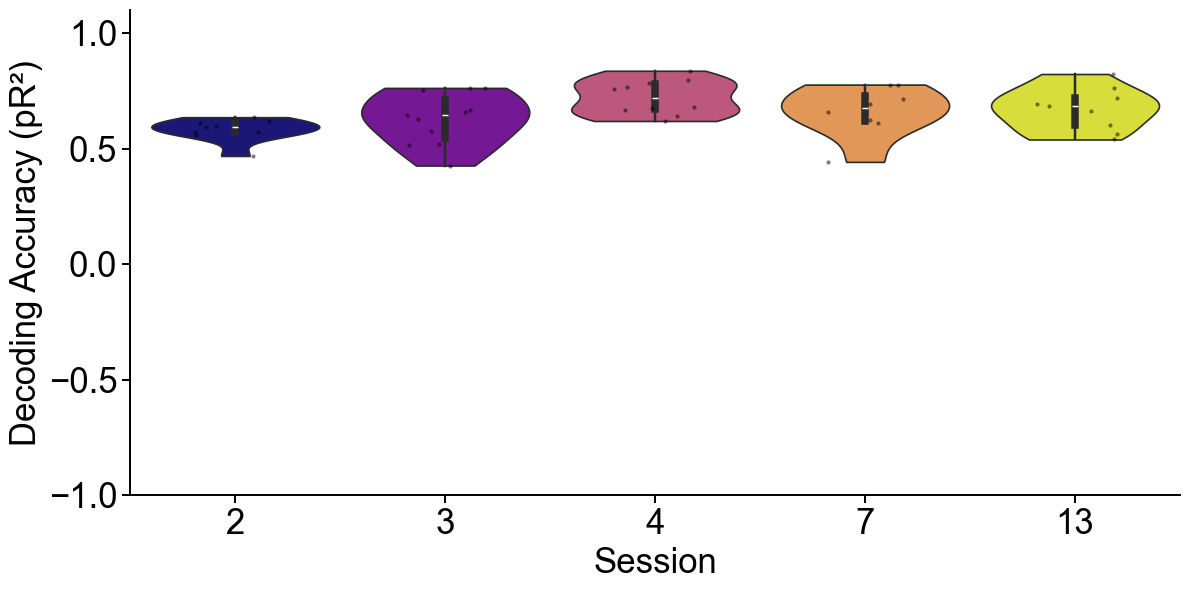

In [10]:
from functions_experimental_data_Bräckleinexp.GLM_analysis_spikes_pred import *

# === Parameters ===
folder_path = '/Users/nmt121/Desktop/DATA/S2/' #path to experimental data
session_files = session_files2 #path to the names of the files

bin_size_ms = 200 
fsamp = 2048 #fsamp exp data
window_duration = 0.3  # for smoothing FR (in seconds)

# Regularization
alpha_grid = {'poissonregressor__alpha': [0.1, 1, 10, 100, 1000]}  
session_results = {}
session_max_firing_rates = {}

def compute_firing_rates(spike_array, fs, window_duration=0.3):
    window_samples = int(round(window_duration * fs))  # Convert duration to samples
    hanning_window = windows.hann(window_samples)  # Create Hanning window
    hanning_window /= np.sum(hanning_window)  # Normalize window
    
    smoothed_firing_rates = np.zeros_like(spike_array, dtype=float)
    
    for i in range(spike_array.shape[0]):  
        smoothed_firing_rates[i, :] = convolve(spike_array[i, :], hanning_window, mode='same') * fs  
    
    return smoothed_firing_rates
# === Cross-validation setup ===
outer_kf = KFold(n_splits=10, shuffle=True, random_state=42)

for session, pkl_files in session_files.items():
    
    session_pR2 = []
    max_frs_this_session = []

    trial_data_list = []
    spike_data_list = []

    for file in pkl_files:
        glm_data, data, mnpair = load_and_preprocess(file, folder_path, bin_size_ms, fsamp)
        trial_data_list.append(glm_data.T)  # (neurons, time_bins)

        data_MU = np.array(data['MU'].tolist())  # (neurons, samples)
        spike_data_list.append(data_MU)

    concatenated_data = np.hstack(trial_data_list)  # (neurons, total_time_bins)
    concatenated_spikes = np.hstack(spike_data_list)  # (neurons, total_samples)
    
    smoothed_frs = compute_firing_rates(data_MU, fsamp, window_duration=0.3) # this is for computing 


    num_neurons = concatenated_data.shape[0]

    for target_idx in range(num_neurons):

        X, Y = create_glm_data(concatenated_data.T, target_idx)
        if X is None or Y is None or np.sum(Y) < 20:
            continue

        # === True max FR based on spike trace ===
        max_fr = np.max(smoothed_frs[target_idx, :])
        max_frs_this_session.append((target_idx, max_fr))

        # === Hyperparameter tuning ===
        pipeline = make_pipeline(StandardScaler(), PoissonRegressor(max_iter=1000))
        inner_kf = KFold(n_splits=3, shuffle=True, random_state=42)
        poisson_cv = GridSearchCV(pipeline, alpha_grid, cv=inner_kf, scoring='neg_mean_poisson_deviance')
        poisson_cv.fit(X, Y)
        best_alpha = poisson_cv.best_params_['poissonregressor__alpha']

        # === Outer CV ===
        fold_pR2s = []
        for train_idx, test_idx in outer_kf.split(X):
            X_train, X_test = X[train_idx], X[test_idx]
            Y_train, Y_test = Y[train_idx], Y[test_idx]

            if np.sum(Y_test) < 5:
                continue

            model = PoissonRegressor(alpha=best_alpha, max_iter=1000)
            model.fit(X_train, Y_train)

            pR2 = compute_pR2(model, X_test, Y_test)
            fold_pR2s.append(pR2)

        if len(fold_pR2s) > 0:
            mean_pR2 = np.nanmean(fold_pR2s)
            session_pR2.append(mean_pR2)

    if len(session_pR2) > 0:
        session_results[session] = session_pR2

    if len(max_frs_this_session) > 0:
        session_max_firing_rates[session] = max_frs_this_session
        print(f"\n=== Max firing rates for session {session} ===")
        for idx, fr in max_frs_this_session:
            print(f"Neuron {idx}: {fr:.2f} Hz")

# === PLOT RESULTS ===
plt.figure(figsize=(12, 6))
plt.rcParams.update({'font.family': 'Arial'})

# Prepare data for seaborn
all_pR2s = []
all_labels = []

simplified_labels = {}
for session in session_results.keys():
    match = re.search(r'(\d+)', session)
    short_label = str(int(match.group(1))) if match else session
    simplified_labels[session] = short_label

for session, pR2_values in session_results.items():
    all_pR2s.extend(pR2_values)
    all_labels.extend([simplified_labels[session]] * len(pR2_values))

unique_sessions = sorted(set(all_labels), key=lambda x: int(x))
N = len(unique_sessions)

cmap = plt.get_cmap('plasma')
colors = [cmap(i / (N - 1)) for i in range(N)]
palette_dict = dict(zip(unique_sessions, colors))

sns.violinplot(x=all_labels, y=all_pR2s, inner='box', linewidth=1.2, palette=palette_dict, cut=0)
sns.stripplot(x=all_labels, y=all_pR2s, color='k', size=3, jitter=0.2, alpha=0.5)

ax = plt.gca()
for spine in ax.spines.values():
    spine.set_linewidth(1.4)

plt.tick_params(width=1.4, length=6, labelsize=25)
plt.xlabel("Session", fontsize=25, fontname="Arial")
plt.ylabel("Decoding Accuracy (pR²)", fontsize=25, fontname="Arial")
plt.ylim([-1, 1.1])
sns.despine(top=True, right=True)

plt.tight_layout()

# plt.savefig('/Users/nmt121/Desktop/Figures/GLM/GLM_Experimental_spikes_S2.pdf', dpi=300, bbox_inches='tight')
plt.show()


## Compute accuracy for simulated data 

In [11]:
# === Input parameters ===
from functions_experimental_data_Bräckleinexp.GLM_analysis_spikes_pred import *
from functions_experimental_data_Bräckleinexp.match_exp_and_sim_data import *

folder_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Spikes/Simulations_with_force_as_input/DR_S2/"

bin_size_ms = 200
fsamp = 20000  # 20 kHz
bin_size_samples = int(bin_size_ms * fsamp / 1000)

# List of your session files (one "day" = one "force" file)
session_files = [
    # 'DR_subject1_force1.jld2',
    # 'DR_subject1_force3.jld2',
    # 'DR_subject1_force4.jld2',
    # 'DR_subject1_force5.jld2',
    # 'DR_subject1_force6.jld2',
    # 'DR_subject1_force7.jld2',
    # 'DR_subject1_force8.jld2',
    # 'DR_subject1_force9.jld2',
    # 'DR_subject1_force10.jld2',
    # 'DR_subject1_force11.jld2',
    # 'DR_subject1_force12.jld2',
    # 'DR_subject1_force13.jld2',
    # 'DR_subject1_force14.jld2',
    
    'DR_subject2_force2.jld2',
    'DR_subject2_force3.jld2',
    'DR_subject2_force4.jld2',
    'DR_subject2_force7.jld2',
    'DR_subject2_force13.jld2',

    # 'DR_subject3_force1.jld2',
    # 'DR_subject3_force2.jld2',
    # 'DR_subject3_force3.jld2',
    # 'DR_subject3_force4.jld2',
    # 'DR_subject3_force5.jld2',
    # 'DR_subject3_force7.jld2',
    # 'DR_subject3_force10.jld2',
    # 'DR_subject3_force11.jld2',
    # 'DR_subject3_force12.jld2',
    # 'DR_subject3_force13.jld2',
    # 'DR_subject3_force14.jld2',
    
    
    # 'DR_subject4_force01.jld2',
    # 'DR_subject4_force03.jld2',
    # 'DR_subject4_force07.jld2',
    # 'DR_subject4_force08.jld2',
    # 'DR_subject4_force09.jld2',
    # 'DR_subject4_force10.jld2',
    # 'DR_subject4_force11.jld2',
    # 'DR_subject4_force12.jld2',
    # 'DR_subject4_force13.jld2',
    # 'DR_subject4_force14.jld2',
]
 

alpha_grid = {'poissonregressor__alpha': [0.1, 1, 10, 100, 1000]}
outer_kf = KFold(n_splits=10, shuffle=True, random_state=42)

session_results = {}

for session_file in session_files:
    session_name = session_file.split('.')[0]  
    print(f"Processing session: {session_name}")
    
    # Load data
    file_path = folder_path + session_file
    with h5py.File(file_path, 'r') as f:
        spike_data = f['spike_array'][:]  
        data = spike_data.T  
    
    # Bin data
    num_neurons, num_samples = data.shape
    num_bins = num_samples // bin_size_samples
    data = data[:, :num_bins * bin_size_samples]
    data_reshaped = data.reshape(num_neurons, num_bins, bin_size_samples)
    binned_data = data_reshaped.sum(axis=2)  # shape: (neurons, time_bins)
    
    session_pR2 = []
    for target_idx in range(num_neurons):
        X, Y = create_glm_data(binned_data.T, target_idx)
        if X is None or Y is None or np.sum(Y) < 20:
            continue

        pipeline = make_pipeline(StandardScaler(), PoissonRegressor(max_iter=1000))
        inner_kf = KFold(n_splits=3, shuffle=True, random_state=42)
        poisson_cv = GridSearchCV(pipeline, alpha_grid, cv=inner_kf, scoring='neg_mean_poisson_deviance')
        poisson_cv.fit(X, Y)
        best_alpha = poisson_cv.best_params_['poissonregressor__alpha']

        # Outer CV
        fold_pR2s = []
        for train_idx, test_idx in outer_kf.split(X):
            X_train, X_test = X[train_idx], X[test_idx]
            Y_train, Y_test = Y[train_idx], Y[test_idx]

            if np.sum(Y_test) < 5:
                continue

            model = PoissonRegressor(alpha=best_alpha, max_iter=1000)
            model.fit(X_train, Y_train)
            pR2 = compute_pR2(model, X_test, Y_test)
            fold_pR2s.append(pR2)

        if len(fold_pR2s) > 0:
            mean_pR2 = np.nanmean(fold_pR2s)
            session_pR2.append(mean_pR2)
            
    print(session_pR2)

    if len(session_pR2) > 0:
        session_results[session_name] = session_pR2

# === PLOT RESULTS ===
# plt.figure(figsize=(8, 5))
# plt.rcParams.update({'font.family': 'Arial'})

# session_means = []
# session_stds = []
# session_labels = []

# for idx, (session, pR2_values) in enumerate(session_results.items()):
#     mean_pR2 = np.nanmean(pR2_values)
#     std_pR2 = np.nanstd(pR2_values)
    
#     session_means.append(mean_pR2)
#     session_stds.append(std_pR2)
#     session_labels.append(session)

#     # Scatter plot neurons' mean pR2 values
#     x_positions = np.full(len(pR2_values), idx)
#     plt.scatter(x_positions, pR2_values, alpha=0.5)


# # Gaussian smoothing of session means
# x_values = np.arange(len(session_means))
# smoothed_means = gaussian_filter1d(session_means, sigma=1)
# plt.plot(x_values, smoothed_means, linestyle='-', color='black', linewidth=2, alpha=0.8)

# plt.xticks(range(len(session_labels)), session_labels, rotation=45, ha='right')
# plt.xlabel("Session (Day)", fontname="Arial")
# plt.ylabel("Decoding Accuracy (pR²)", fontname="Arial")
# plt.ylim([-1, 1.1])
# plt.grid(True)
# plt.tight_layout()
# plt.show()

Processing session: DR_subject2_force2
[0.45996064741908366, 0.6179571048907486, 0.6439987248912443, 0.5761557761357834, 0.48985754243649127, 0.5694551498221722, 0.6003526288106513, 0.6128006228690829, 0.5048370207164905, 0.6135041715314735, 0.40720353388097547, 0.49674300658303117, 0.49583893108039956, 0.37962736325828816, 0.5878860408934774, 0.4138743751972338, 0.480966873380927, 0.6234505776144468, 0.6238793419954481, 0.6159928724622793, 0.6010917827328482, 0.5049624865860298, 0.5128269711978236, 0.5206377144593347, 0.6294072661708972, 0.6023638839000518, 0.4751615394254719, 0.6088433858343648, 0.48907120496170187, 0.5358740200881748, 0.5689980863378447, 0.524283017653085, 0.46503606325103347, 0.5782319677569548, 0.4392523813539841, 0.4441023826010969, 0.4759598839583581, 0.3665909107396995, 0.4518806561628734, 0.4393582278095217, 0.44191925044060065, 0.3892380888800439, 0.4794542308148174, 0.5341888718225316, 0.564959860377225, 0.42580212900779746, 0.5244699457746567, 0.57643208999

### Match neurons of experimental and simulated data

In [12]:
from scipy.optimize import linear_sum_assignment
from functions_experimental_data_Bräckleinexp.firing_rates import *
import h5py, numpy as np, re

def match_experimental_to_simulated(session_files, folder_path, session_results, session_max_firing_rates, fsamp, cost_threshold=5):
    matched_results = {}           # pR² values per session
    matched_sim_indices = {}       # matched simulated neuron indices per session

    for session_file in session_files:
        session_name = session_file.split('.')[0]
        match = re.search(r'force(\d+)', session_file)
        day_number = int(match.group(1)) if match else None
        day_label = f"Day{day_number:02d}"

        if session_name not in session_results:
            continue

        print(f"Matching for {session_name}")
        file_path = folder_path + session_file
        with h5py.File(file_path, 'r') as f:
            spike_data = f['spike_array'][:].T

        firing_rates = compute_firing_rates(spike_data, fsamp)
        max_rates_sim = firing_rates.max(axis=1)

        exp_neurons = session_max_firing_rates.get(day_label, [])
        max_rates_exp = np.array([rate for (_, rate) in exp_neurons])
        if len(max_rates_exp) == 0:
            continue

        cost_matrix = np.abs(max_rates_exp[:, None] - max_rates_sim[None, :])
        row_ind, col_ind = linear_sum_assignment(cost_matrix)

        all_pr2 = session_results[session_name]
        matched_pr2 = []
        matched_indices = []

        for exp_i, sim_j in zip(row_ind, col_ind):
            exp_rate = max_rates_exp[exp_i]
            sim_rate = max_rates_sim[sim_j]
            cost = abs(exp_rate - sim_rate)

            if cost <= cost_threshold:
                if sim_j < len(all_pr2):
                    matched_pr2.append(all_pr2[sim_j])
                    matched_indices.append(sim_j)
                print(f"✓ exp[{exp_i}] (rate={exp_rate:.2f}) ↔ sim[{sim_j}] (rate={sim_rate:.2f}) → cost = {cost:.2f}")
            else:
                print(f"✗ exp[{exp_i}] (rate={exp_rate:.2f}) ↔ sim[{sim_j}] (rate={sim_rate:.2f}) → cost = {cost:.2f} → skipped")

        print(f"→ {session_name}: {len(matched_pr2)} matched neurons (sim neurons: {matched_indices})\n")

        matched_results[session_name] = matched_pr2
        matched_sim_indices[session_name] = matched_indices

    return matched_results, matched_sim_indices

matched_results,matched_sim_indices = match_experimental_to_simulated(session_files=session_files,folder_path=folder_path,session_results=session_results,session_max_firing_rates=session_max_firing_rates,fsamp=fsamp,cost_threshold=10 ) # optional, default is 5Hz of difference)

Matching for DR_subject2_force2
✓ exp[0] (rate=16.20) ↔ sim[169] (rate=16.21) → cost = 0.00
✓ exp[1] (rate=31.18) ↔ sim[66] (rate=21.71) → cost = 9.47
✓ exp[2] (rate=17.33) ↔ sim[145] (rate=17.33) → cost = 0.01
✓ exp[3] (rate=30.05) ↔ sim[68] (rate=21.57) → cost = 8.48
✓ exp[4] (rate=22.05) ↔ sim[64] (rate=21.46) → cost = 0.59
✓ exp[5] (rate=13.24) ↔ sim[179] (rate=15.10) → cost = 1.86
✓ exp[6] (rate=15.21) ↔ sim[174] (rate=15.40) → cost = 0.20
✓ exp[7] (rate=23.66) ↔ sim[55] (rate=21.23) → cost = 2.44
✗ exp[8] (rate=35.99) ↔ sim[90] (rate=21.23) → cost = 14.77 → skipped
→ DR_subject2_force2: 8 matched neurons (sim neurons: [169, 66, 145, 68, 64, 179, 174, 55])

Matching for DR_subject2_force3
✓ exp[0] (rate=15.78) ↔ sim[78] (rate=15.79) → cost = 0.01
✓ exp[1] (rate=16.92) ↔ sim[19] (rate=16.91) → cost = 0.01
✓ exp[2] (rate=15.69) ↔ sim[69] (rate=15.69) → cost = 0.00
✓ exp[3] (rate=13.62) ↔ sim[116] (rate=13.52) → cost = 0.10
✓ exp[4] (rate=14.66) ↔ sim[93] (rate=14.76) → cost = 0.10
✓

/var/folders/xt/z8_l6n9d1wv6vpcb5vdsp1dr0000gq/T/ipykernel_47077/4033432296.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x=all_labels, y=all_pR2s, inner='box', linewidth=1.2,palette=palette_dict, cut=0)


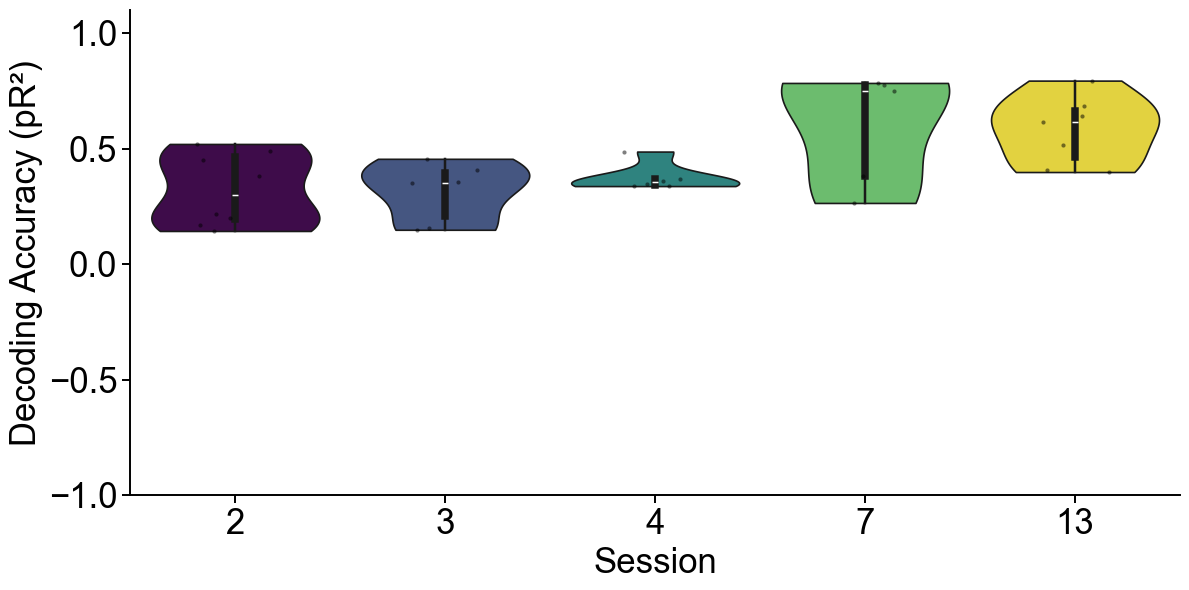

In [13]:
# === PLOT MATCHED pR² VALUES ===
plt.figure(figsize=(12, 6))
plt.rcParams.update({'font.family': 'Arial'})

all_pR2s = []
all_labels = []

for session, pR2_values in matched_results.items():
    session_number = re.findall(r'\d+', session)
    short_label = session_number[-1] if session_number else session  # get last number part
    all_pR2s.extend(pR2_values)
    all_labels.extend([short_label] * len(pR2_values))  # use simplified label

unique_labels = sorted(set(all_labels), key=lambda x: int(x))
N = len(unique_labels)

cmap = plt.get_cmap('viridis')
colors = [cmap(i / (N - 1)) for i in range(N)]

palette_dict = dict(zip(unique_labels, colors))

sns.violinplot(x=all_labels, y=all_pR2s, inner='box', linewidth=1.2,palette=palette_dict, cut=0)
sns.stripplot(x=all_labels, y=all_pR2s, color='k', size=3, jitter=0.2, alpha=0.5)

# Style adjustments
ax = plt.gca()
for spine in ax.spines.values():
    spine.set_linewidth(1.4)

plt.tick_params(width=1.4, length=6, labelsize=25)  # make ticks bigger
plt.xlabel("Session", fontsize=25, fontname="Arial")
plt.ylabel("Decoding Accuracy (pR²)", fontsize=25, fontname="Arial")
plt.xticks(rotation=0, fontsize=25)
plt.ylim([-1, 1.1])
sns.despine(top=True, right=True)
plt.tight_layout()

# plt.savefig('/Users/nmt121/Desktop/Figures/GLM_Simulated_spikes_S2.pdf', dpi=300, bbox_inches='tight')

plt.show()



In [176]:
from scipy.spatial.distance import cdist
from scipy.optimize import linear_sum_assignment
import re
import numpy as np

def match_experimental_to_simulated_time_varying(session_files,
                                                  session_results,
                                                  session_binned_frs,
                                                  simulated_binned_frs,
                                                  distance_threshold=50):
    """
    Match experimental and simulated neurons based on Euclidean distance
    between time-varying firing rate trajectories.
    """
    matched_results = {}
    matched_sim_indices = {}

    for session_file in session_files:
        session_name = session_file.split('.')[0]  # e.g., DR_subject2_force3
        match = re.search(r'force(\d+)', session_file)
        if not match:
            continue
        day_number = int(match.group(1))
        day_label = f"Day{day_number:02d}"

        if session_name not in simulated_binned_frs:
            print(f"Skipping {session_name}: no simulated FRs")
            continue
        if day_label not in session_binned_frs:
            print(f"Skipping {day_label}: no experimental FRs")
            continue
        if session_name not in session_results:
            print(f"Skipping {session_name}: no pR² results")
            continue

        print(f"\n=== Matching {day_label} ↔ {session_name} ===")

        exp_frs = session_binned_frs[day_label]           # shape: (n_exp, T)
        sim_frs = simulated_binned_frs[session_name]      # shape: (n_sim, T)

        # Match time lengths if needed
        min_len = min(exp_frs.shape[1], sim_frs.shape[1])
        exp_frs = exp_frs[:, :min_len]
        sim_frs = sim_frs[:, :min_len]

        # Compute Euclidean distances (cost matrix)
        cost_matrix = cdist(exp_frs, sim_frs, metric='euclidean')

        # Optimal assignment (Hungarian)
        row_ind, col_ind = linear_sum_assignment(cost_matrix)

        # Get pR² values for matched simulated neurons
        all_pr2 = session_results[session_name]
        matched_pr2 = []
        matched_indices = []

        for exp_i, sim_j in zip(row_ind, col_ind):
            dist = cost_matrix[exp_i, sim_j]
            if dist <= distance_threshold:
                if sim_j < len(all_pr2):
                    matched_pr2.append(all_pr2[sim_j])
                    matched_indices.append(sim_j)
                print(f"✓ exp[{exp_i}] ↔ sim[{sim_j}] → dist = {dist:.2f}")
            else:
                print(f"✗ exp[{exp_i}] ↔ sim[{sim_j}] → dist = {dist:.2f} → skipped")

        matched_results[session_name] = matched_pr2
        matched_sim_indices[session_name] = matched_indices

        print(f"→ {session_name}: {len(matched_pr2)} matched neurons")

    return matched_results, matched_sim_indices


# FORCE MODEL

## Compute accuracy for experimental data

/var/folders/xt/z8_l6n9d1wv6vpcb5vdsp1dr0000gq/T/ipykernel_55540/3070554057.py:132: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x=all_labels, y=all_pR2s, inner='box', linewidth=1.2,palette=palette_dict, cut=0)
/var/folders/xt/z8_l6n9d1wv6vpcb5vdsp1dr0000gq/T/ipykernel_55540/3070554057.py:145: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(unique_labels, fontsize=25)


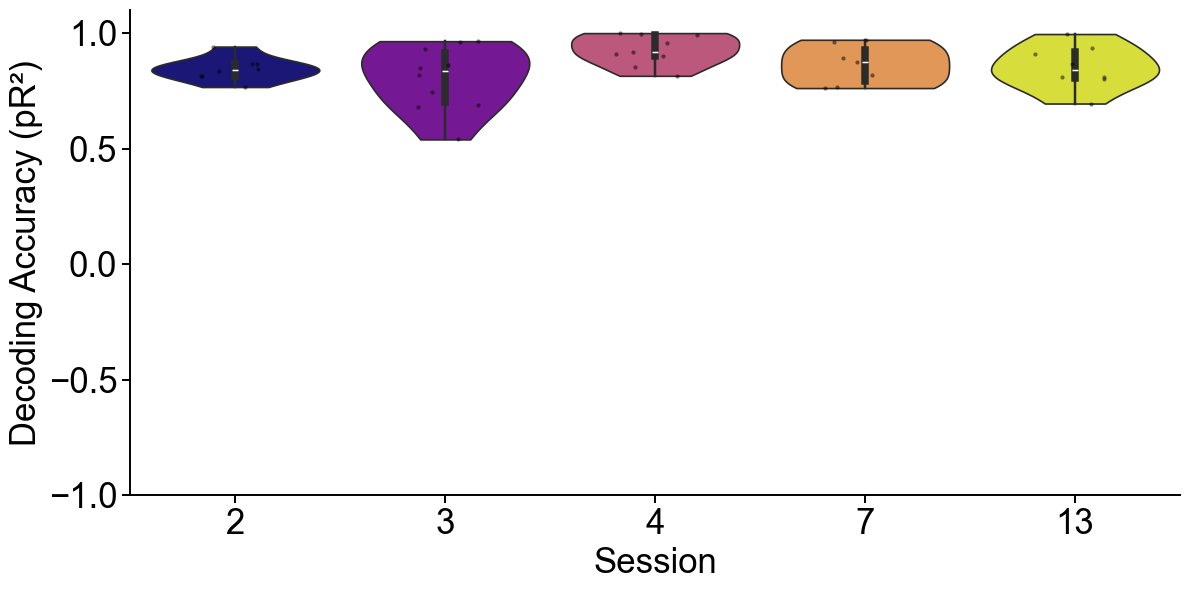

In [156]:
from functions_experimental_data_Bräckleinexp.GLM_analysis_force_pred import *

# === Input parameters ===
folder_path = '/Users/nmt121/Desktop/DATA/S2/'
bin_size_ms = 200  
session_files = session_files2

#regularization 
alpha_grid = {'poissonregressor__alpha': [0.1, 1, 10, 100, 1000]}  
session_results = {}

#init cross val
outer_kf = KFold(n_splits=10, shuffle=True, random_state=42)


def preprocess_trial_force(file, folder_path, bin_size_ms, fsamp=2048):
    file_path = os.path.join(folder_path, file)
    with open(file_path, 'rb') as f:
        data = pickle.load(f)

    force = np.array(data['Force'])
    if force.ndim == 2:
        force = force.squeeze()
        
    data_MU = np.array(data['MU'].tolist())

    # Convert bin size from ms to samples
    bin_size_samples = int(bin_size_ms * fsamp / 1000)

    # Determine number of bins
    num_timepoints = force.shape[0]
    num_bins = num_timepoints // bin_size_samples

    # Bin the spikes and force
    binned_spikes = np.add.reduceat(data_MU, np.arange(0, num_bins * bin_size_samples, bin_size_samples), axis=1)
    binned_force = np.add.reduceat(force[:num_bins * bin_size_samples], np.arange(0, num_bins * bin_size_samples, bin_size_samples)) / bin_size_samples

    mnpair = data['Idx_MU_Pair'].tolist()

    return binned_spikes, binned_force, mnpair


# === MAIN EXECUTION ===
session_results = {}

for session, pkl_files in session_files.items():
    session_pR2 = []
    force_trials = []
    spike_trials = []

    for file in pkl_files:
        spikes, force, mnpair = preprocess_trial_force(file,folder_path, bin_size_ms)
        if spikes is None or force is None:
            continue
        force_trials.append(force)
        spike_trials.append(spikes)

    if not force_trials or not spike_trials:
        continue

    concatenated_force = np.concatenate(force_trials)
    concatenated_spikes = np.hstack(spike_trials)
    num_neurons = concatenated_spikes.shape[0]

    for neuron_idx in range(num_neurons):
        
        if neuron_idx: #== mnpair[0] : #or target_idx == mnpair[1]:

            neuron_spikes = concatenated_spikes[neuron_idx, :]

            X, Y = create_force_glm_data(concatenated_force, neuron_spikes)
            if X is None or Y is None or np.sum(Y) < 20:
                continue

            # === Inner CV for alpha ===
            pipeline = make_pipeline(StandardScaler(), PoissonRegressor(max_iter=1000))
            inner_kf = KFold(n_splits=3, shuffle=True, random_state=42)
            poisson_cv = GridSearchCV(pipeline, alpha_grid, cv=inner_kf, scoring='neg_mean_poisson_deviance')
            poisson_cv.fit(X, Y)
            best_alpha = poisson_cv.best_params_['poissonregressor__alpha']

            # === Outer CV for model performance ===
            fold_pR2s = []
            for train_idx, test_idx in outer_kf.split(X):
                X_train, X_test = X[train_idx], X[test_idx]
                Y_train, Y_test = Y[train_idx], Y[test_idx]

                if np.sum(Y_test) < 5:
                    continue

                scaler = StandardScaler()
                X_train_scaled = scaler.fit_transform(X_train)
                X_test_scaled = scaler.transform(X_test)

                model = PoissonRegressor(alpha=best_alpha, max_iter=1000)
                model.fit(X_train_scaled, Y_train)

                pR2 = compute_pR2(model, X_test_scaled, Y_test)
                fold_pR2s.append(pR2)

            if fold_pR2s:
                mean_pR2 = np.nanmean(fold_pR2s)
                session_pR2.append(mean_pR2)

    if session_pR2:
        session_results[session] = session_pR2

# # === PLOTTING RESULTS ===

plt.figure(figsize=(12, 6))
plt.rcParams.update({'font.family': 'Arial'})

# === Prepare data for seaborn ===
all_pR2s = []
all_labels = []

for session, pR2_values in session_results.items():
    match = re.search(r'(\d+)', session)
    short_label = str(int(match.group(1))) if match else session
    all_pR2s.extend(pR2_values)
    all_labels.extend([short_label] * len(pR2_values))

# === Sort session labels numerically ===
unique_labels = sorted(set(all_labels), key=lambda x: int(x))
N = len(unique_labels)

cmap = plt.get_cmap('plasma')
colors = [cmap(i / (N - 1)) for i in range(N)]
palette_dict = dict(zip(unique_labels, colors))

# === Violin plot ===
sns.violinplot(x=all_labels, y=all_pR2s, inner='box', linewidth=1.2,palette=palette_dict, cut=0)
sns.stripplot(x=all_labels, y=all_pR2s, color='k', size=3, jitter=0.2, alpha=0.5)

# === Style settings ===
ax = plt.gca()
for spine in ax.spines.values():
    spine.set_linewidth(1.4)

plt.tick_params(width=1.4, length=6, labelsize=25)
plt.xlabel("Session", fontsize=25, fontname="Arial")
plt.ylabel("Decoding Accuracy (pR²)", fontsize=25, fontname="Arial")

# Make sure x-ticks are simplified numeric labels
ax.set_xticklabels(unique_labels, fontsize=25)

plt.ylim([-1, 1.1])
sns.despine(top=True, right=True)
plt.tight_layout()

# === Save ===
plt.savefig('/Users/nmt121/Desktop/Figures/GLM/GLM_Experimental_force_S2.pdf', dpi=300, bbox_inches='tight')
plt.show()



## Compute accuracy for simulated data

Processing DR_subject2_force2.jld2 and avg_force_Day_2.npy
Processing DR_subject2_force3.jld2 and avg_force_Day_3.npy
Processing DR_subject2_force4.jld2 and avg_force_Day_4.npy
Processing DR_subject2_force7.jld2 and avg_force_Day_7.npy
Processing DR_subject2_force13.jld2 and avg_force_Day_13.npy


<Figure size 800x500 with 0 Axes>

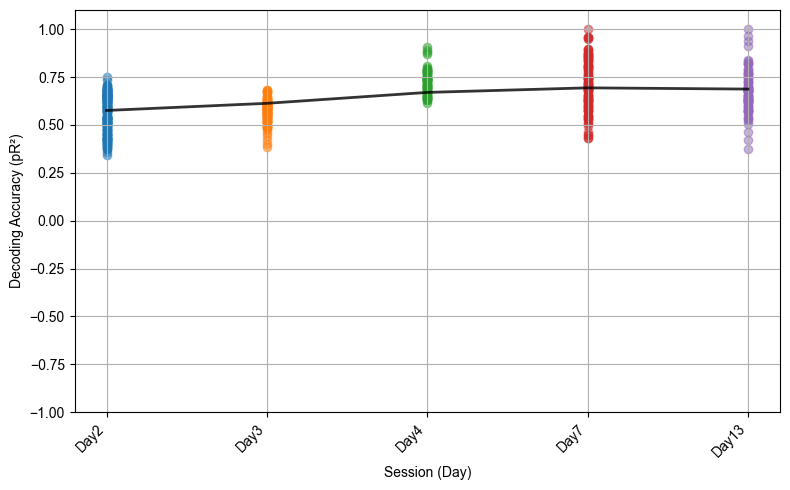

In [158]:
# === Input parameters ===
fsamp_spikes = 20000  # Hz
fsamp_force = 2048    # Hz
bin_size_ms = 200
bin_size_samples = int(bin_size_ms * fsamp_spikes / 1000)

# === Paths ===
spike_folder = 'Data_MN_Model/Data_final/Spikes/Simulations_with_force_as_input/DR_S2'
force_folder = 'Data_MN_Model/Data_final/Scaled_force/S2/'

# === Files for each day ===
session_files = [
    # 'DR_subject1_force1.jld2',
    # 'DR_subject1_force3.jld2',
    # 'DR_subject1_force4.jld2',
    # 'DR_subject1_force5.jld2',
    # 'DR_subject1_force6.jld2',
    # 'DR_subject1_force7.jld2',
    # 'DR_subject1_force8.jld2',
    # 'DR_subject1_force9.jld2',
    # 'DR_subject1_force10.jld2',
    # 'DR_subject1_force11.jld2',
    # 'DR_subject1_force12.jld2',
    # 'DR_subject1_force13.jld2',
    # 'DR_subject1_force14.jld2',
    
    'DR_subject2_force2.jld2',
    'DR_subject2_force3.jld2',
    'DR_subject2_force4.jld2',
    'DR_subject2_force7.jld2',
    'DR_subject2_force13.jld2',
    
    
    # 'DR_subject3_force1.jld2',
    # 'DR_subject3_force2.jld2',
    # 'DR_subject3_force3.jld2',
    # 'DR_subject3_force4.jld2',
    # 'DR_subject3_force5.jld2',
    # 'DR_subject3_force7.jld2',
    # 'DR_subject3_force10.jld2',
    # 'DR_subject3_force11.jld2',
    # 'DR_subject3_force12.jld2',
    # 'DR_subject3_force13.jld2',
    
    # 'DR_subject4_force01.jld2',
    # 'DR_subject4_force03.jld2',
    # 'DR_subject4_force07.jld2',
    # 'DR_subject4_force08.jld2',
    # 'DR_subject4_force09.jld2',
    # 'DR_subject4_force10.jld2',
    # 'DR_subject4_force11.jld2',
    # 'DR_subject4_force12.jld2',
    # 'DR_subject4_force13.jld2',
    # 'DR_subject4_force14.jld2',
    
]
 
# Map days based on session_files order
# day_mapping=  [ '1', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14']
day_mapping = [ '2','3', '4', '7','13']  
# day_mapping=  [ '1', '2', '3', '4', '5', '7', '10', '11', '12', '13', '14']
# day_mapping=  [ '1', '3', '7', '8', '9', '10', '11', '12', '13', '14']

alpha_grid = {'poissonregressor__alpha': [0.1, 1, 10, 100, 1000]}
outer_kf = KFold(n_splits=10, shuffle=True, random_state=42)

# === Utility functions ===
def preprocess_force_npy(file_path, fsamp_force, fsamp_target, target_samples, bin_size_samples):
    # Load force data from .npy file
    force = np.load(file_path)
    
    n_force = len(force)
    t_force = np.arange(n_force) / fsamp_force
    t_target = np.arange(target_samples) / fsamp_target
    force_interp = interp1d(t_force, force, kind='linear', fill_value='extrapolate')
    force_resampled = force_interp(t_target)
    
    n_bins = target_samples // bin_size_samples
    force_resampled = force_resampled[:n_bins * bin_size_samples]
    force_reshaped = force_resampled.reshape(n_bins, bin_size_samples)
    binned_force = force_reshaped.mean(axis=1)
    
    return binned_force

# === MAIN EXECUTION ===
session_results = {}

for idx, spike_file in enumerate(session_files):  # Iterate directly over the session_files
    day = day_mapping[idx]  # Get the corresponding day from day_mapping
    force_file = f"avg_force_Day_{day}.npy"  # Construct correct file name based on the day
    print(f"Processing {spike_file} and {force_file}")

    # Load spikes (using jld2 format for spike data)
    with h5py.File(os.path.join(spike_folder, spike_file), 'r') as f:
        spike_data = f['spike_array'][:]  # shape: (neurons, samples)
        spikes = spike_data.T  # Transpose to shape: (samples, neurons)

    # Bin spikes (same as second script)
    num_neurons, num_samples = spikes.shape
    num_bins = num_samples // bin_size_samples
    spikes = spikes[:, :num_bins * bin_size_samples]
    spikes_reshaped = spikes.reshape(num_neurons, num_bins, bin_size_samples)
    binned_spikes = spikes_reshaped.sum(axis=2)  # shape: (neurons, time_bins)

    # Preprocess force
    binned_force = preprocess_force_npy(
        os.path.join(force_folder, force_file),
        fsamp_force,
        fsamp_spikes,
        spikes.shape[1],
        bin_size_samples
    )

    # Predict each neuron
    session_pR2 = []
    for neuron_idx in range(spikes.shape[0]):
        neuron_spikes = binned_spikes[neuron_idx, :]

        X, Y = create_force_glm_data(binned_force, neuron_spikes)
        if X is None or Y is None or np.sum(Y) < 20:
            continue

        # Inner CV for alpha
        pipeline = make_pipeline(StandardScaler(), PoissonRegressor(max_iter=1000))
        inner_kf = KFold(n_splits=3, shuffle=True, random_state=42)
        poisson_cv = GridSearchCV(pipeline, alpha_grid, cv=inner_kf, scoring='neg_mean_poisson_deviance')
        poisson_cv.fit(X, Y)
        best_alpha = poisson_cv.best_params_['poissonregressor__alpha']

        # Outer CV for pR²
        fold_pR2s = []
        for train_idx, test_idx in outer_kf.split(X):
            X_train, X_test = X[train_idx], X[test_idx]
            Y_train, Y_test = Y[train_idx], Y[test_idx]

            if np.sum(Y_test) < 5:
                continue

            scaler = StandardScaler()
            X_train_scaled = scaler.fit_transform(X_train)
            X_test_scaled = scaler.transform(X_test)

            model = PoissonRegressor(alpha=best_alpha, max_iter=1000)
            model.fit(X_train_scaled, Y_train)

            pR2 = compute_pR2(model, X_test_scaled, Y_test)
            fold_pR2s.append(pR2)

        if fold_pR2s:
            mean_pR2 = np.nanmean(fold_pR2s)
            session_pR2.append((neuron_idx, mean_pR2))  # store index + value


    if session_pR2:
        session_results[f"Day{day}"] = dict(session_pR2)

# === Plotting results ===
plt.figure(figsize=(8, 5))
plt.rcParams.update({'font.family': 'Arial'})

session_means = []
session_stds = []
session_labels = []

plt.figure(figsize=(8, 5))
plt.rcParams.update({'font.family': 'Arial'})

session_means = []
session_stds = []
session_labels = []

# Sort session labels numerically (e.g., Day2, Day3, Day4...)
sorted_sessions = sorted(session_results.keys(), key=lambda s: int(s.replace("Day", "")))

for idx, session_name in enumerate(sorted_sessions):
    pr2_dict = session_results[session_name]
    pR2_values = list(pr2_dict.values())  # get list of pR² values

    if not pR2_values:
        continue

    mean_pR2 = np.nanmean(pR2_values)
    std_pR2 = np.nanstd(pR2_values)

    session_means.append(mean_pR2)
    session_stds.append(std_pR2)
    session_labels.append(session_name)

    x_positions = np.full(len(pR2_values), idx)
    plt.scatter(x_positions, pR2_values, alpha=0.5)

# Smoothed mean line
x_vals = np.arange(len(session_means))
if len(session_means) > 1:
    smoothed_means = gaussian_filter1d(session_means, sigma=1)
else:
    smoothed_means = session_means

plt.plot(x_vals, smoothed_means, linestyle='-', color='black', linewidth=2, alpha=0.8)

# Plot formatting
plt.xticks(range(len(session_labels)), session_labels, rotation=45, ha='right')
plt.xlabel("Session (Day)", fontname="Arial")
plt.ylabel("Decoding Accuracy (pR²)", fontname="Arial")
plt.ylim([-1, 1.1])
plt.grid(True)
plt.tight_layout()
plt.show()


### Matching

Day2
[0.49442514509244473, 0.678207927223567, 0.41112746195348315, 0.49175522958871787, 0.618568380990166, 0.6426694487095362, 0.5706683450620698, 0.6027190327105009]
Day3
[0.6469688031447235, 0.5160355321025014, 0.552932839801943, 0.683324060284819, 0.5872225048740264]
Day4
[0.6397960026293669, 0.6498299740837552, 0.6416666390486497, 0.6397012212510538, 0.665587476575747]
Day7
[0.8550760726166541, 0.6410445482632465, 0.8116247302398149, 0.8764055194128797, 0.4331504252242245]
Day13
[0.5379384043794695, 0.6696397615348904, 0.5987631167669644, 0.6951368675381067, 0.8245206649408142, 0.677706636371501, 0.6953239375664492]


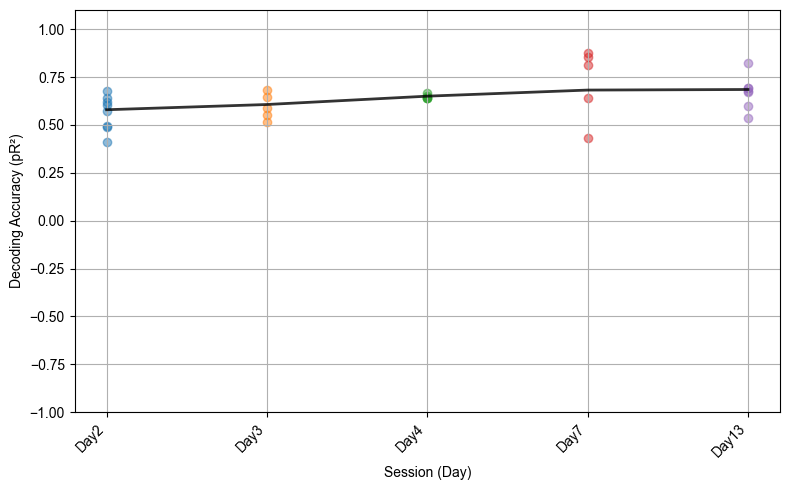

In [ ]:
# Assuming:
# - matched_sim_indices = {'DR_subject2_force2': [2, 23, 0], ...}
# - session_results = {'Day2': {0: pr², 1: pr², ...}, ...}

plt.figure(figsize=(8, 5))
plt.rcParams.update({'font.family': 'Arial'})

session_means = []
session_stds = []
session_labels = []

# === Map session filenames to Day labels
day_labels = {

'DR_subject2_force2': 'Day2','DR_subject2_force3': 'Day3','DR_subject2_force4': 'Day4','DR_subject2_force7': 'Day7','DR_subject2_force13': 'Day13'

# 'DR_subject1_force1': 'Day1', 'DR_subject1_force3': 'Day3', 'DR_subject1_force4': 'Day4','DR_subject1_force5': 'Day5', 'DR_subject1_force6': 'Day6', 'DR_subject1_force7': 'Day7','DR_subject1_force8': 'Day8', 'DR_subject1_force9': 'Day9', 'DR_subject1_force10': 'Day10','DR_subject1_force11': 'Day11', 'DR_subject1_force12': 'Day12', 'DR_subject1_force13': 'Day13','DR_subject1_force14': 'Day14'

# 'DR_subject3_force1': 'Day1', 'DR_subject3_force2': 'Day2', 'DR_subject3_force3': 'Day3', 'DR_subject3_force4': 'Day4', 'DR_subject3_force5': 'Day5', 'DR_subject3_force7': 'Day7', 'DR_subject3_force10': 'Day10', 'DR_subject3_force11': 'Day11', 'DR_subject3_force12': 'Day12', 'DR_subject3_force13': 'Day13'

# 'DR_subject4_force01': 'Day1', 'DR_subject4_force03': 'Day3', 'DR_subject4_force07': 'Day7','DR_subject4_force08': 'Day8', 'DR_subject4_force09': 'Day9', 'DR_subject4_force10': 'Day10','DR_subject4_force11': 'Day11', 'DR_subject4_force12': 'Day12', 'DR_subject4_force13': 'Day13','DR_subject4_force14': 'Day14'

}

# === Sort by numeric day
sorted_sessions = sorted(matched_sim_indices.keys(), key=lambda s: int(re.search(r'force(\d+)', s).group(1)))

for idx, session_name in enumerate(sorted_sessions):
    matched_indices = matched_sim_indices[session_name]
    day_label = day_labels.get(session_name)
    print(day_label)
    if day_label not in session_results:
        continue

    pr2_dict = session_results[day_label]

    # Only take pR² values for matched simulated neurons
    filtered_pR2 = [pr2_dict[i] for i in matched_indices if i in pr2_dict]
    print(filtered_pR2)

    if not filtered_pR2:
        continue

    mean_pR2 = np.nanmean(filtered_pR2)
    std_pR2 = np.nanstd(filtered_pR2)

    session_means.append(mean_pR2)
    session_stds.append(std_pR2)
    session_labels.append(day_label)

    x_positions = np.full(len(filtered_pR2), len(session_means) - 1)
    plt.scatter(x_positions, filtered_pR2, alpha=0.5)

# Smoothed mean line
x_vals = np.arange(len(session_means))
if len(session_means) > 1:
    smoothed_means = gaussian_filter1d(session_means, sigma=1)
else:
    smoothed_means = session_means

plt.plot(x_vals, smoothed_means, linestyle='-', color='black', linewidth=2, alpha=0.8)

# Plot formatting
plt.xticks(range(len(session_labels)), session_labels, rotation=45, ha='right')
plt.xlabel("Session (Day)", fontname="Arial")
plt.ylabel("Decoding Accuracy (pR²)", fontname="Arial")
plt.ylim([-1, 1.1])
plt.grid(True)
plt.tight_layout()
plt.show()


/var/folders/xt/z8_l6n9d1wv6vpcb5vdsp1dr0000gq/T/ipykernel_55540/485533875.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x=all_labels, y=all_pR2s, inner='box', linewidth=1.2, palette=palette_dict, cut=0)
/var/folders/xt/z8_l6n9d1wv6vpcb5vdsp1dr0000gq/T/ipykernel_55540/485533875.py:51: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(numeric_labels, fontsize=25, rotation=0)


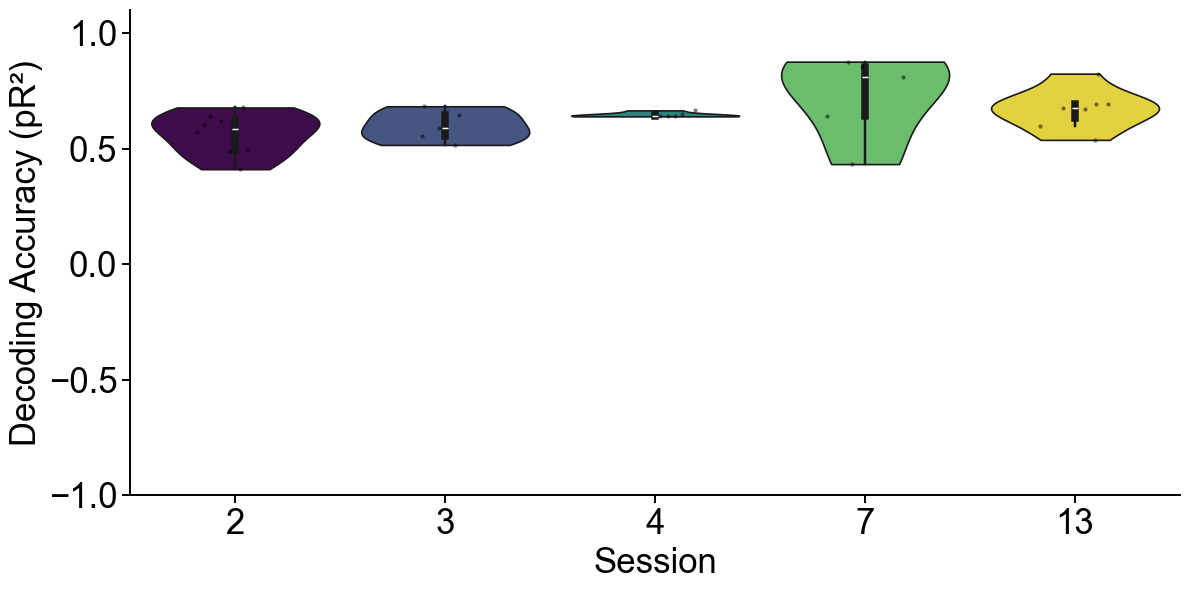

In [160]:
# === Initialize lists for plotting
all_pR2s = []
all_labels = []

# === Sort session names by numeric day index extracted from the session name
sorted_sessions = sorted(matched_sim_indices.keys(), key=lambda s: int(re.search(r'force(\d+)', s).group(1)))

for session_name in sorted_sessions:
    matched_indices = matched_sim_indices[session_name]
    day_label = day_labels.get(session_name)

    if day_label not in session_results:
        continue

    pr2_dict = session_results[day_label]

    # Get filtered pR² values only for matched simulated neurons
    filtered_pR2 = [pr2_dict[i] for i in matched_indices if i in pr2_dict]

    if not filtered_pR2:
        continue

    all_pR2s.extend(filtered_pR2)
    all_labels.extend([day_label] * len(filtered_pR2))

# === Unique sorted labels
unique_labels = sorted(set(all_labels), key=lambda s: int(re.search(r'Day(\d+)', s).group(1)))
N = len(unique_labels)

# === Color palette
cmap = plt.get_cmap('viridis')
colors = [cmap(i / (N - 1)) for i in range(N)]
palette_dict = dict(zip(unique_labels, colors))

# === Plot
plt.figure(figsize=(12, 6))
sns.violinplot(x=all_labels, y=all_pR2s, inner='box', linewidth=1.2, palette=palette_dict, cut=0)
sns.stripplot(x=all_labels, y=all_pR2s, color='k', size=3, jitter=0.2, alpha=0.5)

# === Style
ax = plt.gca()
for spine in ax.spines.values():
    spine.set_linewidth(1.4)

plt.tick_params(width=1.4, length=6, labelsize=25)
plt.xlabel("Session", fontsize=25, fontname="Arial")
plt.ylabel("Decoding Accuracy (pR²)", fontsize=25, fontname="Arial")
# === Remove "Day" from x-axis tick labels
current_labels = [tick.get_text() for tick in ax.get_xticklabels()]
numeric_labels = [re.sub(r'Day', '', label) for label in current_labels]
ax.set_xticklabels(numeric_labels, fontsize=25, rotation=0)
plt.ylim([-1, 1.1])
sns.despine(top=True, right=True)
plt.tight_layout()

# === Save figure
plt.savefig('/Users/nmt121/Desktop/Figures/GLM_Simulated_force_S2.pdf', dpi=300, bbox_inches='tight')
plt.show()
